# Enzyme knockouts in a GECKO model of yeast

GECKO models extend a genome-scale metabolic model with enzyme constraints: each reaction consumes its enzyme in proportion to its flux (1/kcat per unit of flux), and the enzymes are drawn from a protein pool of limited total mass. This example uses the ecYeastGEM model (batch, v8.1.3) with a single protein pool, which ships with MEWpy, to

1. simulate the wild type and inspect protein usage;
2. apply constraints on enzyme usage;
3. search for enzyme knockouts (`GeckoKOProblem`) and enzyme over/under expression (`GeckoOUProblem`) that make yeast secrete succinate.

`mewpy.model.gecko.GeckoModel` loads the model with REFRAMED, and MEWpy solves it with its default solver (SCIP here). MEWpy also accepts the COBRApy-based `geckopy.gecko.GeckoModel`; with COBRApy's GLPK solver, however, the LPs of this model are much slower.

Each LP on this model takes one to two seconds, so the optimizations use very small settings (population size and number of generations) to keep the notebook within a few minutes. They show how the problems are set up and what they return, not good designs.

In [1]:
import logging

import pandas as pd

import mewpy
from mewpy.model.gecko import GeckoModel
from mewpy.optimization import EA
from mewpy.optimization.evaluation import BPCY, WYIELD
from mewpy.problems import GeckoKOProblem, GeckoOUProblem
from mewpy.simulation import get_simulator
from mewpy.visualization.envelope import plot_flux_envelope

# MEWpy logs the fitness statistics of each generation at INFO level; jMetalPy logs at DEBUG level by default.
mewpy.configure_logging("INFO")
logging.getLogger("jmetal").setLevel(logging.WARNING)

model = GeckoModel('single-pool')
print('reactions: %d, proteins: %d' % (len(model.reactions), len(model.proteins)))

reactions: 6910, proteins: 816


## Wild type

Reversible reactions are split into two irreversible ones in GECKO models, so the glucose uptake is the forward flux of `r_1714_REV` ("D-glucose exchange (reversible)"). It is limited to 10 mmol/gDW/h. The biomass reaction is `r_2111` and the succinate exchange `r_2056`.

In [2]:
BIOMASS = 'r_2111'
PRODUCT = 'r_2056'
envcond = {'r_1714_REV': (0, 10)}

simul = get_simulator(model, envcond=envcond)
result = simul.simulate()
print(result)

Simulation Result
Status:              OPTIMAL
Objective (maximize): 0.313741
Method:              FBA
Model:               M_ecYeastGEM_batch_v8__46__1__46__3
Fluxes:              746 non-zero / 6910 total
Constraints:         1
  Environment:       1


Each enzyme is supplied by a draw reaction, `draw_prot_<UniProt id>`, whose flux is the enzyme's usage (mmol/gDW). `protein_reactions` lists the reactions that use an enzyme.

In [3]:
print({r: model.reactions[r].name for r in simul.protein_reactions('P52867')})
result.find('draw_prot_P52867')

{'r_0362No2': 'dolichyl-phosphate-mannose--protein mannosyltransferase (No2)'}


,Flux rate
Reaction ID,
draw_prot_P52867,6.340474e-07


Parsimonious FBA (pFBA) minimises the total flux while keeping the growth at 99.9% of its maximum. In the wild type, succinate is not secreted, although flux variability analysis (FVA, at 90% of the maximal growth by default) shows that it could be.

In [4]:
wild_type = simul.simulate(method='pFBA')
print('growth: %.4f 1/h, succinate: %.4f mmol/gDW/h' % (wild_type.fluxes[BIOMASS], wild_type.fluxes[PRODUCT]))
simul.FVA(reactions=[PRODUCT])

growth: 0.3134 1/h, succinate: 0.0000 mmol/gDW/h


{'r_2056': [0.0, 1.494658430765412]}

## Constraints on enzyme usage

Constraints on draw reactions limit how much of an enzyme the cell can use. The set below is an example: it limits the usage of two enzymes well below their wild-type usage, deletes a third (P39006) and leaves a fourth, unused in the wild type, effectively unconstrained.

In [5]:
constraints = {'draw_prot_P13188': (0.0, 9.3e-07),
               'draw_prot_P39006': 0.0,
               'draw_prot_P08067': (0.0, 2.7e-07),
               'draw_prot_P38791': (0.0, 10000)}

pd.DataFrame({'wild-type usage': {r: wild_type.fluxes[r] for r in constraints},
              'constraint': constraints})

,wild-type usage,constraint
draw_prot_P13188,3.579533e-06,"(0.0, 9.3e-07)"
draw_prot_P39006,8.160094e-09,0.0
draw_prot_P08067,1.849680e-05,"(0.0, 2.7e-07)"
draw_prot_P38791,0.000000e+00,"(0.0, 10000)"


In [6]:
constrained = simul.simulate(constraints=constraints, method='pFBA')
print('growth: %.4f 1/h, succinate: %.4f mmol/gDW/h' % (constrained.fluxes[BIOMASS], constrained.fluxes[PRODUCT]))
simul.FVA(reactions=[PRODUCT], constraints=constraints)

growth: 0.0814 1/h, succinate: 0.0261 mmol/gDW/h


{'r_2056': [0.0, 5.978636567013382]}

With these constraints, pFBA predicts a lower growth rate and some succinate secretion. The production envelope shows the succinate range at each growth rate:

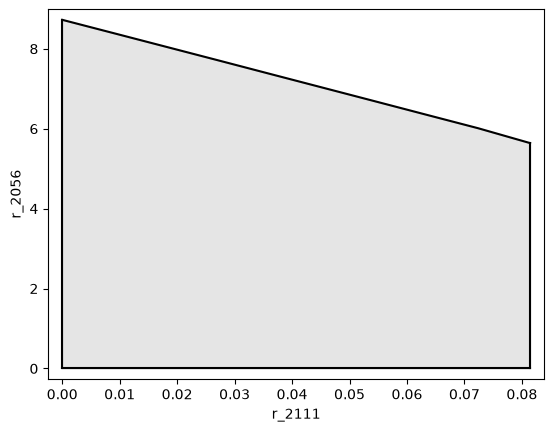

In [7]:
plot_flux_envelope(simul, BIOMASS, PRODUCT, constraints=constraints);

## Optimization

The objectives are the same as in the GOUProblem example (`05-GOUproblem.ipynb`):

- `BPCY`: growth × succinate flux, both predicted by linear MOMA (lMOMA, the flux distribution closest to the wild-type pFBA fluxes);
- `WYIELD`: 0.3 × maximum + 0.7 × minimum succinate flux over the flux distributions with at least 99% of the mutant's maximal growth (0 below 10% of the wild-type growth).

In [8]:
def objectives():
    return [BPCY(BIOMASS, PRODUCT, method='lMOMA'), WYIELD(BIOMASS, PRODUCT)]

Targets are given by protein id (not by draw reaction id). Without a `target` list, `GeckoKOProblem` first computes the essential proteins, one FBA per protein (816 here), which takes longer than the rest of this notebook. To keep the example short, the targets are the proteins used in the wild-type pFBA solution, essential or not; candidates that cannot grow simply get the worst fitness.

In [9]:
targets = sorted(p for p in simul.proteins if wild_type.fluxes['draw_prot_' + p] > 0)
print('targets: %d of %d proteins' % (len(targets), len(simul.proteins)))

targets: 251 of 816 proteins


### Knockouts

Candidates delete 1 to 4 enzymes. The EA (NSGA-II) runs 5 generations of 18 candidates (90 evaluations). The candidates are evaluated in parallel by Ray workers (the default, `mp=True`); Ray logs a few lines when it starts. `seed` sets the EA's random choices; as with any EA, another run can return different solutions. `simplify=False` skips the simplification of the final solutions (one evaluation per modification, plus one, for each solution); one solution is simplified further below.

In [10]:
ko_problem = GeckoKOProblem(model, objectives(), envcond=envcond, target=targets, candidate_max_size=4)
ko_ea = EA(ko_problem, max_generations=5, population_size=18, seed=42)
ko_pop = ko_ea.run(simplify=False)
ko_df = ko_ea.dataframe()
ko_df.sort_values('BPCY', ascending=False)

2026-11-09 23:21:08,665	INFO util.py:155 -- Outdated packages:
  ipywidgets==7.8.5 found, needs ipywidgets>=8
Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-11-09 23:21:08,937	WARNING authentication_token_setup.py:85 -- Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html


2026-11-09 23:21:13,088	INFO worker.py:2038 -- Started a local Ray instance.


[2026-11-09 23:21:15] [mewpy.util.process] [INFO] Using 6 workers.


[2026-11-09 23:21:15] [mewpy.optimization.jmetal.ea] [INFO] Running NSGAII


[2026-11-09 23:21:34] [mewpy] [INFO] Eval(s)|     Worst      Best    Median   Average   Std Dev|     Worst      Best    Median   Average   Std Dev|
     18|  0.000000  0.000420  0.000000  0.000023  0.000096|  0.000000  0.051155  0.000000  0.005504  0.015576|


[2026-11-09 23:21:44] [mewpy] [INFO]      36|  0.000000  0.000420  0.000000  0.000023  0.000096|  0.000000  0.051155  0.000000  0.010799  0.020216|


[2026-11-09 23:21:57] [mewpy] [INFO]      54|  0.000000  0.000420  0.000000  0.000047  0.000132|  0.000000  0.051182  0.047911  0.035064  0.021780|


[2026-11-09 23:22:13] [mewpy] [INFO]      72|  0.000000  0.000420  0.000000  0.000140  0.000198|  0.047911  0.051182  0.049406  0.049522  0.001612|


[2026-11-09 23:22:30] [mewpy] [INFO]      90|  0.000000  0.000420  0.000420  0.000257  0.000205|  0.051155  0.052637  0.051155  0.051246  0.000338|


,Modification,Size,BPCY,WYIELD
0,{'draw_prot_P00410': 0},1,0.00042,0.051155
1,"{'draw_prot_P38620': 0, 'draw_prot_P32473': 0}",2,0.00000,0.052637
2,{'draw_prot_Q12455': 0},1,0.00000,0.051182


The solution with the highest BPCY is simplified (modifications that do not change its fitness are removed), and the mutant is simulated with lMOMA and pFBA. The table names the reactions that use each deleted enzyme.

In [11]:
def enzyme_reactions(draw_id):
    protein = draw_id[len('draw_prot_'):]
    return ', '.join(sorted({model.reactions[r].name for r in simul.protein_reactions(protein)}))


def inspect(problem, solution):
    simplified = problem.simplify(solution)[0]
    print('modifications:', simplified.values)
    print('fitness (BPCY, WYIELD):', [round(f, 6) for f in simplified.fitness])
    reactions = {p: enzyme_reactions(p) for p in simplified.values}
    display(pd.DataFrame({'level': simplified.values, 'reactions': reactions}))
    rows = {}
    for method in ['lMOMA', 'pFBA']:
        res = problem.simulate(solution=simplified.values, method=method)
        rows[method] = {'growth': res.fluxes[BIOMASS], 'succinate': res.fluxes[PRODUCT]}
    return pd.DataFrame(rows).T


inspect(ko_problem, ko_pop[ko_df['BPCY'].idxmax()])

modifications: {'draw_prot_P00410': 0}
fitness (BPCY, WYIELD): [0.00042, 0.051155]


,level,reactions
draw_prot_P00410,0,"ferrocytochrome-c:oxygen oxidoreductase (No1),..."


,growth,succinate
lMOMA,0.055213,0.007614
pFBA,0.179240,0.018261


Deleting P00410, an enzyme of ferrocytochrome-c:oxygen oxidoreductase (respiratory complex IV), gives the highest BPCY: lMOMA predicts a growth rate of 0.0552 1/h and 0.00761 mmol/gDW/h of succinate (0.0552 × 0.00761 = 0.00042). At maximal growth (pFBA), the same mutant grows faster (0.179 1/h) and secretes more succinate (0.018 mmol/gDW/h).

### Over/under expression

`GeckoOUProblem` sets a level for each modified enzyme: 0 deletes it, a level below 1 caps its usage at that fraction of its wild-type (pFBA) usage, and a level above 1 forces a usage of at least that multiple. It runs here with the same targets, objectives and population size, for 4 generations (72 evaluations) to keep the runtime down.

In [12]:
ou_problem = GeckoOUProblem(model, objectives(), envcond=envcond, target=targets, candidate_max_size=4)
ou_ea = EA(ou_problem, max_generations=4, population_size=18, seed=42)
ou_pop = ou_ea.run(simplify=False)
ou_df = ou_ea.dataframe()
ou_df.sort_values('BPCY', ascending=False)

2026-11-09 23:22:43,907	INFO worker.py:1855 -- Calling ray.init() again after it has already been called.


[2026-11-09 23:22:44] [mewpy.util.process] [INFO] Using 6 workers.


[2026-11-09 23:22:44] [mewpy.optimization.jmetal.ea] [INFO] Running NSGAII


[2026-11-09 23:23:09] [mewpy] [INFO] Eval(s)|     Worst      Best    Median   Average   Std Dev|     Worst      Best    Median   Average   Std Dev|
     18|  0.000000  0.000000  0.000000  0.000000  0.000000|  0.000000  3.106140  0.020265  0.477396  1.042560|


[2026-11-09 23:23:22] [mewpy] [INFO]      36|  0.000000  0.000000  0.000000  0.000000  0.000000|  0.000000  3.106140  0.059838  0.947331  1.291802|


[2026-11-09 23:23:39] [mewpy] [INFO]      54|  0.000000  0.000000  0.000000  0.000000  0.000000|  0.068024  3.106140  2.670724  2.399666  0.931117|


[2026-11-09 23:24:02] [mewpy] [INFO]      72|  0.000000  0.000000  0.000000  0.000000  0.000000|  3.106066  3.106140  3.106140  3.106128  0.000028|


,Modification,Size,BPCY,WYIELD
0,{'draw_prot_P32377': 0.125},1,0.0,3.106140
1,{'draw_prot_P16603': 0.125},1,0.0,3.106066


In [13]:
inspect(ou_problem, ou_pop[ou_df['BPCY'].idxmax()])

modifications: {'draw_prot_P32377': 0.125}
fitness (BPCY, WYIELD): [0.0, 3.10614]


,level,reactions
draw_prot_P32377,0.125,mevalonate pyrophoshate decarboxylase (No1)


,growth,succinate
lMOMA,0.039178,0.0
pFBA,0.039139,0.0


In [14]:
pd.DataFrame({
    'evaluations': [ko_ea.max_generations * ko_ea.population_size, ou_ea.max_generations * ou_ea.population_size],
    'best BPCY': [ko_df['BPCY'].max(), ou_df['BPCY'].max()],
    'best WYIELD': [ko_df['WYIELD'].max(), ou_df['WYIELD'].max()],
}, index=['GeckoKOProblem', 'GeckoOUProblem'])

,evaluations,best BPCY,best WYIELD
GeckoKOProblem,90,0.00042,0.052637
GeckoOUProblem,72,0.00000,3.106140


The over/under expression run returns two solutions, each capping one enzyme at 1/8 of its wild-type usage: P32377 (mevalonate pyrophosphate decarboxylase) or P16603. Both have a BPCY of 0, and the first is the one inspected above: the mutant grows at 0.039 1/h (0.313 1/h in the wild type) and secretes no succinate with lMOMA or pFBA, but its WYIELD (3.106) is the highest of both runs. In this run the knockouts reached the higher BPCY and the over/under expression the higher WYIELD; with 90 and 72 evaluations, this shows what each problem returns rather than which strategy is better.